In [1]:
#%matplotlib 

In [2]:
import argparse
import os
import random
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data
import torchvision.datasets as datasets
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import torchvision.utils as vutils
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from  IPython.display import HTML

# set random seed for reproducibility
manualSeed = 999

print("Random Seed: ", manualSeed)
random.seed(manualSeed)
torch.manual_seed(manualSeed)
torch.use_deterministic_algorithms(True)  # Needed for reproducible results

Random Seed:  999


### Create the dataset

In [3]:
class ImageProcessor:
    def __init__(self, root_dir_path, transformations=None):
        self.root_dir_path = root_dir_path
        self.transformations = transformations

        self.all_img_paths = [
            entry.path
            for entry in os.scandir(root_dir_path)
            if entry.is_file()
            and entry.name.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

    def __len__(self):
        return len(self.all_img_paths)

    def __getitem__(self, idx):
        img_path = self.all_img_paths[idx]

        with Image.open(img_path) as image:
            img = image.convert("RGB")

        if self.transformations:
            img = self.transformations(img)

        return img

In [4]:
root_dir_path = "/kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba/img_align_celeba"

transformations = transforms.Compose([
    transforms.CenterCrop(178),  # 178x218 => 178x178
    transforms.Resize(64), # 64x64
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) #[-1,1]
])

loaded 202599 images


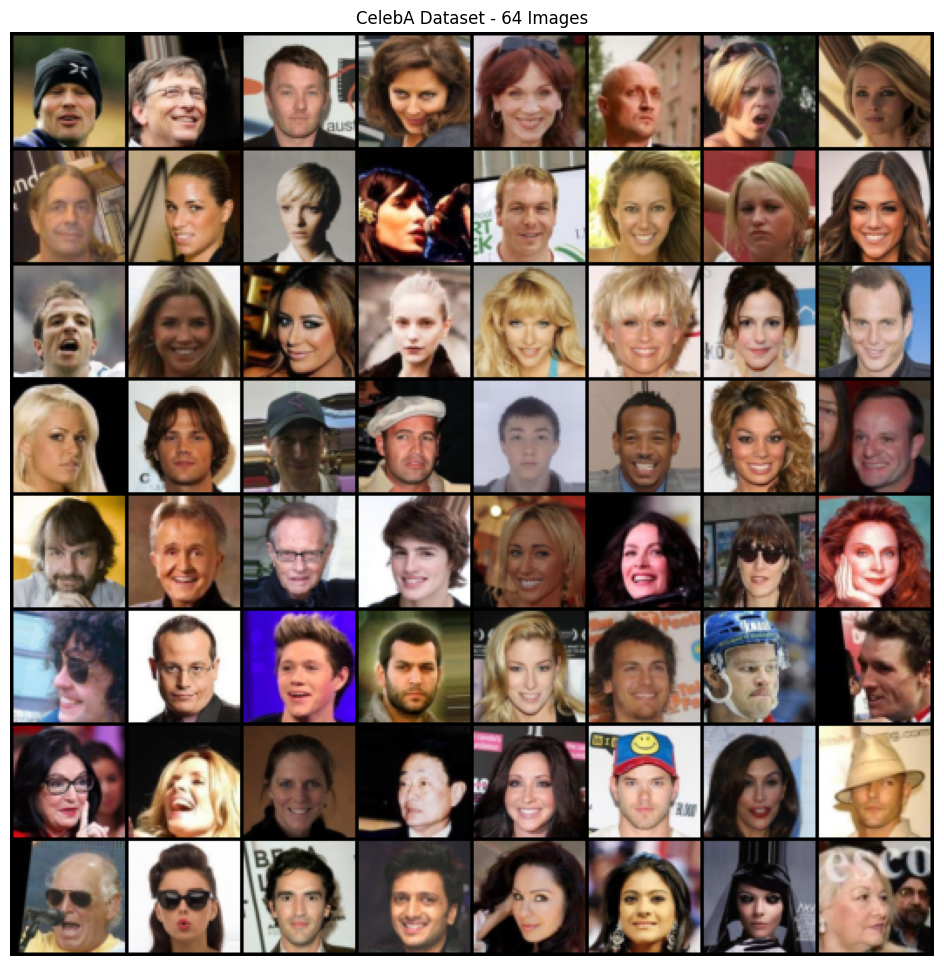

In [5]:
dataset = ImageProcessor(root_dir_path, transformations)
print(f"loaded {len(dataset)} images")

# Create the dataloader
dataloader = DataLoader(
    dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

real_batch = next(iter(dataloader))
# Select 64 images
images = real_batch[:64]

# Create grid
grid = vutils.make_grid(
    images,
    nrow=8,
    padding=2,
    normalize=True
)

# Display grid
plt.figure(figsize=(12, 12))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("CelebA Dataset - 64 Images")
plt.show()

### Weight Initialization
all model weights shall be randomly initialized from a Normal distribution with mean=0, stdev=0.02.

In [6]:
# custom weights initialization called on ``netG`` and ``netD``
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

### Generator 

In [7]:
class Generator(nn.Module):
    def __init__(self, z=100, img_channels=3, ngf=64):
        super(Generator, self).__init__()
    
        self.main = nn.Sequential(
            nn.ConvTranspose2d( z, ngf * 8, kernel_size=4, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),
            # state size. ``(ngf*8) x 4 x 4``
            
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            # state size. ``(ngf*4) x 8 x 8``
            
            nn.ConvTranspose2d( ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            # state size. ``(ngf*2) x 16 x 16``
            
            nn.ConvTranspose2d( ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            # state size. ``(ngf) x 32 x 32``
            
            nn.ConvTranspose2d( ngf, img_channels, 4, 2, 1, bias=False),
            nn.Tanh()
            # state size. ``3 x 64 x 64``
        )

    def forward(self, z):
        return self.main(z)

### Discriminator

In [8]:
class Discriminator(nn.Module):
    def __init__(self, img_channels=3,  ndf=64):
        super(Discriminator, self).__init__()
    
        self.main = nn.Sequential(
            # input is ``3 x 64 x 64``
            nn.Conv2d(img_channels, ndf, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(ndf),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. ``(ndf) x 32 x 32``
            
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. ``(ndf*2) x 16 x 16``
            
            nn.Conv2d( ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. ``(ngf*4) x 8 x 8``
            
            nn.Conv2d( ndf * 4, ndf * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 8),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. ``(ndf) x 4 x 4``
            
            nn.Conv2d( ndf * 8, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.main(z)

In [ ]:
# Device selection
if torch.backends.mps.is_available():
    device = torch.device("mps")

elif torch.cuda.is_available():
    device = torch.device("cuda:0")
    
else:
    device = torch.device("cpu")

print(f"Device is {device}")

Device is cuda:0


In [ ]:
# Create the generator
netG = Generator().to(device)
# Apply the ``weights_init`` function to randomly initialize all weights
#  to ``mean=0``, ``stdev=0.02``.
netG.apply(weights_init)
print(netG)

# Create the Discriminator
netD = Discriminator().to(device)
# Apply the ``weights_init`` function to randomly initialize all weights
# like this: ``to mean=0, stdev=0.2``.
netD.apply(weights_init)
print(netD)

Generator(
  (main): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh()
  )
)


### Loss Functions and Optimizers

In [11]:
# Initialize the ``BCELoss`` function
criterion = nn.BCELoss()

fixed_noise = torch.randn(16, 100, 1, 1, device=device)

# Establish convention for real and fake labels during training
real_label = 1.
fake_label = 0.

# Setup Adam optimizers for both G and D
optimizerD = optim.Adam(netD.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=0.0002, betas=(0.5, 0.999))

### Training

In [12]:
def train(netG, netD, dataloader, checkpoint_path="/kaggle/working/checkpoints/gan_checkpoint.pth", resume=False):
    # Lists to keep track of progress
    G_losses = []
    D_losses = []
    start_epoch = 1
    if resume:
        checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
        netG.load_state_dict(checkpoint['generator_state_dict'])
        netD.load_state_dict(checkpoint['discriminator_state_dict'])
    
        optimizerG.load_state_dict(checkpoint['optimizerG_state_dict'])
        optimizerD.load_state_dict(checkpoint['optimizerD_state_dict'])
        
        start_epoch = checkpoint["epoch"] + 1
        # Restore previous losses
        G_losses = checkpoint['G_losses']
        D_losses = checkpoint['D_losses']

    epoch = start_epoch
    print("Starting Training Loop...")
    # For each epoch
    while True:
        # For each batch in the dataloader
        for i, data in enumerate(dataloader):
    
            ############################
            # (1) Update D network: maximize log(D(x)) + log(1 - D(G(z)))
            ###########################
            ## Train with all-real batch
            netD.zero_grad()
            # Format batch
            real_cpu = data.to(device)
            b_size = real_cpu.size(0)
            label = torch.full((b_size,), real_label, dtype=torch.float, device=device)
            # Forward pass real batch through D
            output = netD(real_cpu).view(-1)
            # Calculate loss on all-real batch
            errD_real = criterion(output, label)
            # Calculate gradients for D in backward pass
            errD_real.backward()
            D_x = output.mean().item()
    
            ## Train with all-fake batch
            # Generate batch of latent vectors
            noise = torch.randn(b_size, 100, 1, 1, device=device)
            # Generate fake image batch with G
            fake = netG(noise)
            label.fill_(fake_label)
            # Classify all fake batch with D
            output = netD(fake.detach()).view(-1)
            # Calculate D's loss on the all-fake batch
            errD_fake = criterion(output, label)
            # Calculate the gradients for this batch, accumulated (summed) with previous gradients
            errD_fake.backward()
            D_G_z1 = output.mean().item()
            # Compute error of D as sum over the fake and the real batches
            errD = errD_real + errD_fake
            # Update D
            optimizerD.step()
    
            ############################
            # (2) Update G network: maximize log(D(G(z)))
            ###########################
            netG.zero_grad()
            label.fill_(real_label)  # fake labels are real for generator cost
            # Since we just updated D, perform another forward pass of all-fake batch through D
            output = netD(fake).view(-1)
            # Calculate G's loss based on this output
            errG = criterion(output, label)
            # Calculate gradients for G
            errG.backward()
            D_G_z2 = output.mean().item()
            # Update G
            optimizerG.step()
    
            # Output training stats
            if i % 50 == 0:
                print(
                    f'epoch:[{epoch}] [batch:{i+1}/{len(dataloader)}]\t'
                    f'Loss_D: {errD.item():.4f}\t'
                    f'Loss_G: {errG.item():.4f}\t'
                    f'D(x): {D_x:.4f}\t'
                    f'D(G(z)): {D_G_z1:.4f} / {D_G_z2:.4f}')
                
            # Save Losses for plotting later
            G_losses.append(errG.item())
            D_losses.append(errD.item())
            
        
        # Save training state after each completed epoch so training can be resumed.
        checkpoint_dir = os.path.dirname(checkpoint_path)
        if checkpoint_dir:
            os.makedirs(checkpoint_dir, exist_ok=True)
        torch.save({
            "epoch": epoch,
            'generator_state_dict': netG.state_dict(),
            'discriminator_state_dict': netD.state_dict(),
            'optimizerG_state_dict': optimizerG.state_dict(),
            'optimizerD_state_dict': optimizerD.state_dict(),
            # Save losses
            'G_losses': G_losses,
            'D_losses': D_losses,
        }, checkpoint_path)
        save_generated_images(netG, epoch, device, fixed_noise)
        epoch += 1

In [13]:
import matplotlib.pyplot as plt
import torchvision

def save_generated_images(netG, epoch, device, fixed_noise):
    was_training = netG.training
    netG.eval()

    with torch.no_grad():
        generated_imgs = netG(fixed_noise).cpu()

    if was_training:
        netG.train()

    
    grid = torchvision.utils.make_grid(
        generated_imgs,
        nrow=4,
        normalize=True
    )

    # Create output directory
    os.makedirs("outputs", exist_ok=True)

    # Save generated image
    save_path = f"outputs/epoch_{epoch:03d}.png"
    torchvision.utils.save_image(grid, save_path)

    if (epoch == 1 or epoch % 5 == 0):
        # Display generated image
        plt.figure(figsize=(8, 8))
        plt.imshow(np.transpose(grid, (1, 2, 0)))
        plt.title(f"Epoch {epoch}")
        plt.axis("off")
        plt.show()

    print(f"Generated images saved: {save_path}")

Starting Training Loop...


epoch:[1] [batch:1/1583]	Loss_D: 1.5232	Loss_G: 6.1582	D(x): 0.6528	D(G(z)): 0.5856 / 0.0033


epoch:[1] [batch:51/1583]	Loss_D: 0.1588	Loss_G: 7.7738	D(x): 0.9790	D(G(z)): 0.0910 / 0.0018


epoch:[1] [batch:101/1583]	Loss_D: 0.3315	Loss_G: 13.1452	D(x): 0.9282	D(G(z)): 0.1499 / 0.0000


epoch:[1] [batch:151/1583]	Loss_D: 0.8530	Loss_G: 12.5075	D(x): 0.9748	D(G(z)): 0.4743 / 0.0001


epoch:[1] [batch:201/1583]	Loss_D: 0.3278	Loss_G: 4.8831	D(x): 0.8856	D(G(z)): 0.1567 / 0.0111


... (23 outputs left out)

epoch:[1] [batch:1401/1583]	Loss_D: 0.4278	Loss_G: 3.7231	D(x): 0.8631	D(G(z)): 0.2037 / 0.0445


epoch:[1] [batch:1451/1583]	Loss_D: 1.3665	Loss_G: 1.4785	D(x): 0.3838	D(G(z)): 0.0282 / 0.3162


epoch:[1] [batch:1501/1583]	Loss_D: 0.4305	Loss_G: 3.9680	D(x): 0.8844	D(G(z)): 0.2258 / 0.0346


epoch:[1] [batch:1551/1583]	Loss_D: 0.7309	Loss_G: 3.5731	D(x): 0.7557	D(G(z)): 0.2903 / 0.0444


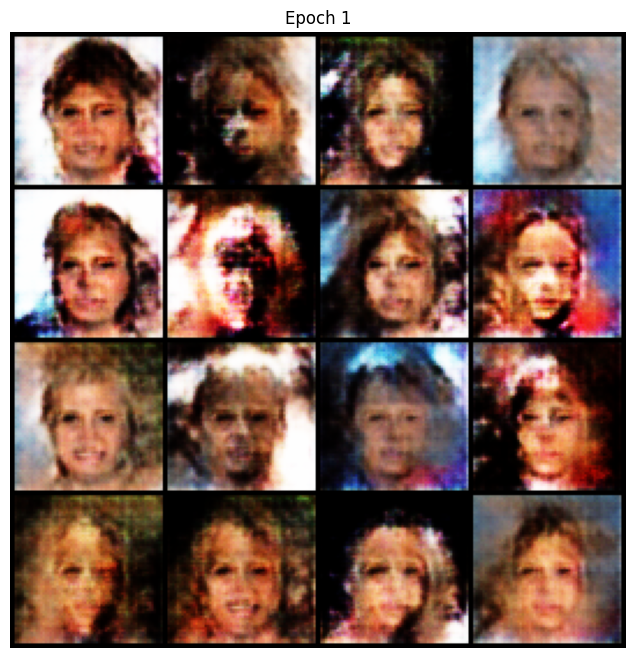

Generated images saved: outputs/epoch_001.png


epoch:[2] [batch:1/1583]	Loss_D: 0.4295	Loss_G: 4.1452	D(x): 0.8629	D(G(z)): 0.1957 / 0.0253


epoch:[2] [batch:51/1583]	Loss_D: 0.5084	Loss_G: 3.4179	D(x): 0.7798	D(G(z)): 0.1400 / 0.0616


epoch:[2] [batch:101/1583]	Loss_D: 0.5503	Loss_G: 2.3270	D(x): 0.6673	D(G(z)): 0.0485 / 0.1509


epoch:[2] [batch:151/1583]	Loss_D: 0.3322	Loss_G: 4.6214	D(x): 0.9221	D(G(z)): 0.1953 / 0.0164


epoch:[2] [batch:201/1583]	Loss_D: 0.4912	Loss_G: 2.4774	D(x): 0.7387	D(G(z)): 0.0813 / 0.1333


... (122 outputs left out)

epoch:[5] [batch:1401/1583]	Loss_D: 1.2038	Loss_G: 4.7867	D(x): 0.9480	D(G(z)): 0.6288 / 0.0123


epoch:[5] [batch:1451/1583]	Loss_D: 0.5050	Loss_G: 2.2663	D(x): 0.7586	D(G(z)): 0.1687 / 0.1323


epoch:[5] [batch:1501/1583]	Loss_D: 0.6493	Loss_G: 2.0103	D(x): 0.7058	D(G(z)): 0.2101 / 0.1661


epoch:[5] [batch:1551/1583]	Loss_D: 0.5800	Loss_G: 1.8572	D(x): 0.7074	D(G(z)): 0.1625 / 0.1952


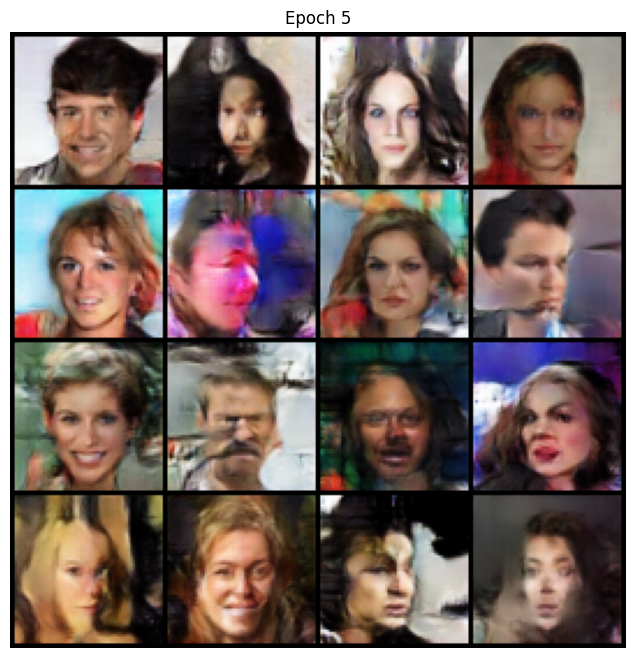

Generated images saved: outputs/epoch_005.png


epoch:[6] [batch:1/1583]	Loss_D: 0.7072	Loss_G: 1.3175	D(x): 0.5699	D(G(z)): 0.0616 / 0.3248


epoch:[6] [batch:51/1583]	Loss_D: 0.4865	Loss_G: 2.4208	D(x): 0.8337	D(G(z)): 0.2362 / 0.1099


epoch:[6] [batch:101/1583]	Loss_D: 0.4092	Loss_G: 2.9550	D(x): 0.8319	D(G(z)): 0.1778 / 0.0696


epoch:[6] [batch:151/1583]	Loss_D: 0.5667	Loss_G: 1.9855	D(x): 0.6702	D(G(z)): 0.0980 / 0.1734


epoch:[6] [batch:201/1583]	Loss_D: 0.6521	Loss_G: 1.4892	D(x): 0.6225	D(G(z)): 0.1012 / 0.2959


... (155 outputs left out)

epoch:[10] [batch:1401/1583]	Loss_D: 0.3582	Loss_G: 3.3042	D(x): 0.9044	D(G(z)): 0.2048 / 0.0512


epoch:[10] [batch:1451/1583]	Loss_D: 0.4258	Loss_G: 2.5951	D(x): 0.6996	D(G(z)): 0.0272 / 0.1121


epoch:[10] [batch:1501/1583]	Loss_D: 0.3401	Loss_G: 3.9632	D(x): 0.9317	D(G(z)): 0.2135 / 0.0266


epoch:[10] [batch:1551/1583]	Loss_D: 0.4581	Loss_G: 2.3074	D(x): 0.7073	D(G(z)): 0.0548 / 0.1464


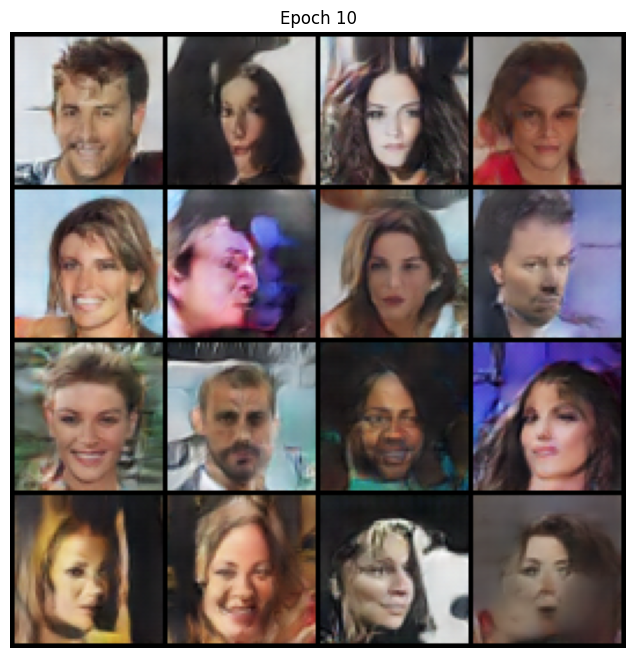

Generated images saved: outputs/epoch_010.png


epoch:[11] [batch:1/1583]	Loss_D: 0.2904	Loss_G: 2.6846	D(x): 0.8087	D(G(z)): 0.0579 / 0.0930


epoch:[11] [batch:51/1583]	Loss_D: 0.3535	Loss_G: 2.9517	D(x): 0.8759	D(G(z)): 0.1761 / 0.0704


epoch:[11] [batch:101/1583]	Loss_D: 0.3212	Loss_G: 3.5395	D(x): 0.9365	D(G(z)): 0.2035 / 0.0417


epoch:[11] [batch:151/1583]	Loss_D: 0.2704	Loss_G: 3.7547	D(x): 0.9433	D(G(z)): 0.1751 / 0.0344


epoch:[11] [batch:201/1583]	Loss_D: 0.2571	Loss_G: 3.0683	D(x): 0.8454	D(G(z)): 0.0676 / 0.0704


... (155 outputs left out)

epoch:[15] [batch:1401/1583]	Loss_D: 0.4098	Loss_G: 2.0644	D(x): 0.7586	D(G(z)): 0.0649 / 0.1819


epoch:[15] [batch:1451/1583]	Loss_D: 0.1390	Loss_G: 4.1514	D(x): 0.9463	D(G(z)): 0.0733 / 0.0254


epoch:[15] [batch:1501/1583]	Loss_D: 0.2467	Loss_G: 2.3845	D(x): 0.8343	D(G(z)): 0.0399 / 0.1361


epoch:[15] [batch:1551/1583]	Loss_D: 0.2134	Loss_G: 5.0670	D(x): 0.9595	D(G(z)): 0.1442 / 0.0098


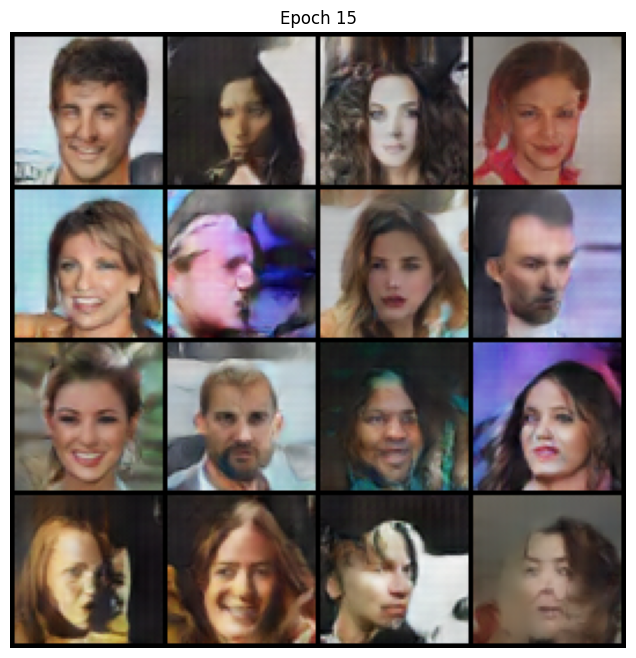

Generated images saved: outputs/epoch_015.png


epoch:[16] [batch:1/1583]	Loss_D: 0.9191	Loss_G: 2.6946	D(x): 0.7320	D(G(z)): 0.3575 / 0.1017


epoch:[16] [batch:51/1583]	Loss_D: 0.4256	Loss_G: 2.7037	D(x): 0.7305	D(G(z)): 0.0481 / 0.1226


epoch:[16] [batch:101/1583]	Loss_D: 0.2831	Loss_G: 4.6256	D(x): 0.9516	D(G(z)): 0.1777 / 0.0168


epoch:[16] [batch:151/1583]	Loss_D: 0.1432	Loss_G: 3.7072	D(x): 0.9238	D(G(z)): 0.0526 / 0.0386


epoch:[16] [batch:201/1583]	Loss_D: 0.1246	Loss_G: 3.5870	D(x): 0.9598	D(G(z)): 0.0759 / 0.0402


... (155 outputs left out)

epoch:[20] [batch:1401/1583]	Loss_D: 0.1249	Loss_G: 3.7980	D(x): 0.9636	D(G(z)): 0.0775 / 0.0373


epoch:[20] [batch:1451/1583]	Loss_D: 0.0535	Loss_G: 4.5248	D(x): 0.9762	D(G(z)): 0.0275 / 0.0202


epoch:[20] [batch:1501/1583]	Loss_D: 0.0820	Loss_G: 4.9113	D(x): 0.9835	D(G(z)): 0.0593 / 0.0134


epoch:[20] [batch:1551/1583]	Loss_D: 0.2028	Loss_G: 3.6982	D(x): 0.8926	D(G(z)): 0.0648 / 0.0599


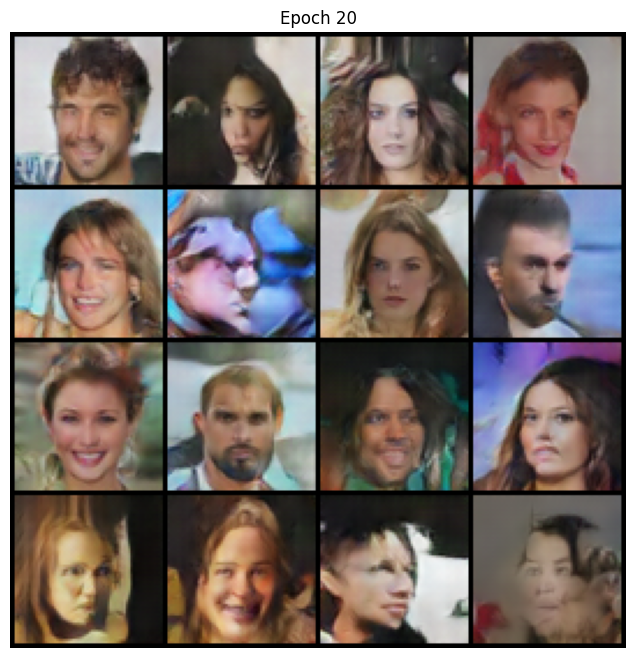

Generated images saved: outputs/epoch_020.png


epoch:[21] [batch:1/1583]	Loss_D: 3.3759	Loss_G: 1.3977	D(x): 0.0982	D(G(z)): 0.0039 / 0.4019


epoch:[21] [batch:51/1583]	Loss_D: 0.1302	Loss_G: 5.4877	D(x): 0.9808	D(G(z)): 0.0922 / 0.0083


epoch:[21] [batch:101/1583]	Loss_D: 0.1807	Loss_G: 3.3116	D(x): 0.8658	D(G(z)): 0.0196 / 0.0684


epoch:[21] [batch:151/1583]	Loss_D: 0.7544	Loss_G: 2.3206	D(x): 0.6625	D(G(z)): 0.1711 / 0.1479


epoch:[21] [batch:201/1583]	Loss_D: 0.1534	Loss_G: 4.8999	D(x): 0.9633	D(G(z)): 0.0979 / 0.0134


... (155 outputs left out)

epoch:[25] [batch:1401/1583]	Loss_D: 0.6667	Loss_G: 1.8858	D(x): 0.7081	D(G(z)): 0.1893 / 0.2315


epoch:[25] [batch:1451/1583]	Loss_D: 0.3015	Loss_G: 4.1847	D(x): 0.9158	D(G(z)): 0.1534 / 0.0304


epoch:[25] [batch:1501/1583]	Loss_D: 0.2664	Loss_G: 3.2490	D(x): 0.8195	D(G(z)): 0.0321 / 0.0780


epoch:[25] [batch:1551/1583]	Loss_D: 0.2304	Loss_G: 3.6448	D(x): 0.9622	D(G(z)): 0.1526 / 0.0487


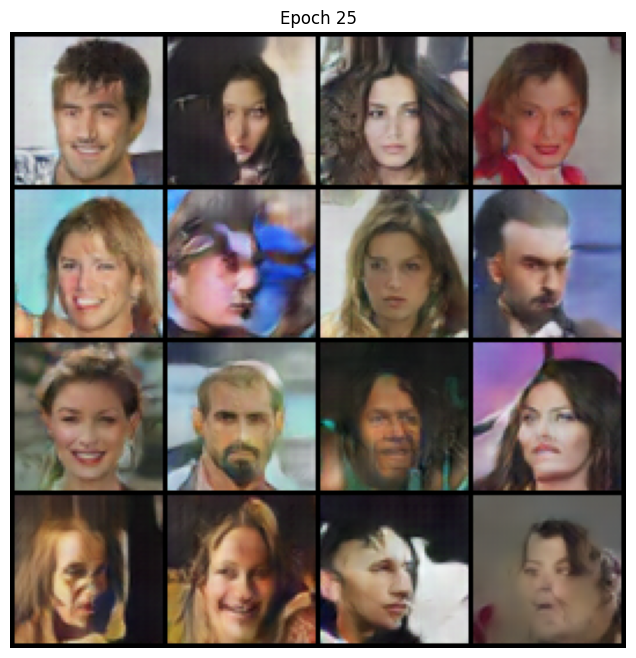

Generated images saved: outputs/epoch_025.png


epoch:[26] [batch:1/1583]	Loss_D: 0.1411	Loss_G: 4.2549	D(x): 0.9476	D(G(z)): 0.0720 / 0.0302


epoch:[26] [batch:51/1583]	Loss_D: 0.1868	Loss_G: 2.7582	D(x): 0.8636	D(G(z)): 0.0242 / 0.1165


epoch:[26] [batch:101/1583]	Loss_D: 0.2095	Loss_G: 5.1190	D(x): 0.9372	D(G(z)): 0.1071 / 0.0121


epoch:[26] [batch:151/1583]	Loss_D: 0.0549	Loss_G: 4.9792	D(x): 0.9643	D(G(z)): 0.0170 / 0.0149


epoch:[26] [batch:201/1583]	Loss_D: 0.0581	Loss_G: 5.3627	D(x): 0.9726	D(G(z)): 0.0273 / 0.0109


... (155 outputs left out)

epoch:[30] [batch:1401/1583]	Loss_D: 0.0444	Loss_G: 4.7955	D(x): 0.9761	D(G(z)): 0.0184 / 0.0176


epoch:[30] [batch:1451/1583]	Loss_D: 0.0612	Loss_G: 5.6167	D(x): 0.9965	D(G(z)): 0.0533 / 0.0085


epoch:[30] [batch:1501/1583]	Loss_D: 0.0491	Loss_G: 5.0692	D(x): 0.9690	D(G(z)): 0.0158 / 0.0126


epoch:[30] [batch:1551/1583]	Loss_D: 1.0695	Loss_G: 2.6498	D(x): 0.6524	D(G(z)): 0.2542 / 0.2002


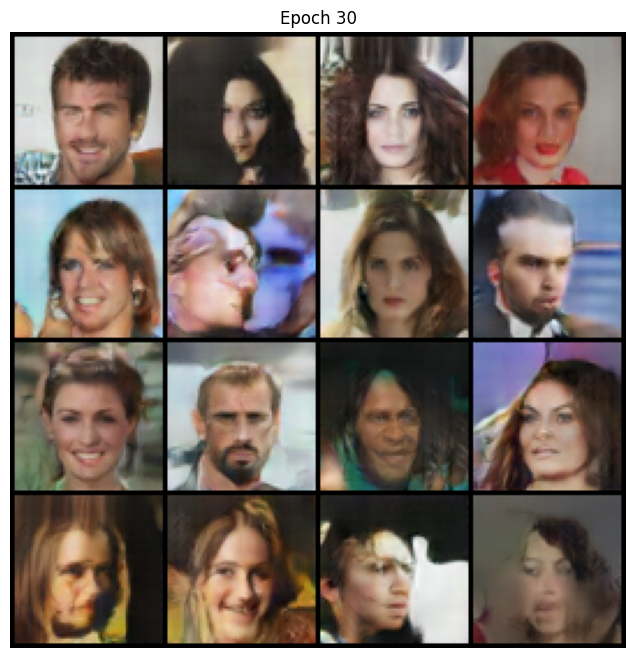

Generated images saved: outputs/epoch_030.png


epoch:[31] [batch:1/1583]	Loss_D: 0.4244	Loss_G: 3.1988	D(x): 0.7371	D(G(z)): 0.0308 / 0.1021


epoch:[31] [batch:51/1583]	Loss_D: 0.1300	Loss_G: 4.4390	D(x): 0.9082	D(G(z)): 0.0186 / 0.0359


epoch:[31] [batch:101/1583]	Loss_D: 0.1482	Loss_G: 6.7156	D(x): 0.9924	D(G(z)): 0.1122 / 0.0025


epoch:[31] [batch:151/1583]	Loss_D: 0.0408	Loss_G: 7.1288	D(x): 0.9672	D(G(z)): 0.0055 / 0.0024


epoch:[31] [batch:201/1583]	Loss_D: 0.3887	Loss_G: 3.2799	D(x): 0.8061	D(G(z)): 0.0914 / 0.0848


... (56 outputs left out)

epoch:[32] [batch:1401/1583]	Loss_D: 0.0743	Loss_G: 5.3419	D(x): 0.9479	D(G(z)): 0.0160 / 0.0150


epoch:[32] [batch:1451/1583]	Loss_D: 0.0450	Loss_G: 5.1610	D(x): 0.9761	D(G(z)): 0.0177 / 0.0137


epoch:[32] [batch:1501/1583]	Loss_D: 0.4250	Loss_G: 2.5881	D(x): 0.8073	D(G(z)): 0.1131 / 0.1339


epoch:[32] [batch:1551/1583]	Loss_D: 0.2227	Loss_G: 3.0126	D(x): 0.8465	D(G(z)): 0.0150 / 0.1094


In [14]:

train(netG, netD, dataloader)